# NLP Hands-on on `Airline Passengers Tweets Data`

#### Load the certain key libraries

In [12]:
# pip install contractions

In [13]:
import re, string, unicodedata # import Regex, String and unicodedata
import contractions            # Import contractions library
from bs4 import BeautifulSoup  # Import BeautifulSoup


import numpy as np
import pandas as pd
import nltk                   ## Import Natural Language Tool-kit


nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')

from nltk.corpus import stopwords                       # Import stopwords.
from nltk.tokenize import word_tokenize, sent_tokenize  # Import Tokenizer.
from nltk.stem.wordnet import WordNetLemmatizer         # Import Lemmatizer.

[nltk_data] Downloading package stopwords to C:\Users\Sonal
[nltk_data]     Thorat\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to C:\Users\Sonal
[nltk_data]     Thorat\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\Sonal
[nltk_data]     Thorat\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [15]:
#### let us see the current working directory
os.getcwd()

'c:\\Users\\Sonal Thorat\\Desktop\\Intellipaat python code\\Projects\\NLP -AIRLINE PASENGERS TWEETS'

### Load the `Twitter Airline Passengers' Dataset`

In [16]:
data = pd.read_csv("Tweets.csv")

In [17]:
data.sample(3).T

,12243,5631,1703
tweet_id,570253932880007000,568849739346608000,569620002652889000
airline_sentiment,negative,negative,negative
airline_sentiment_confidence,0.6687,1.0,1.0
negativereason,Flight Booking Problems,Late Flight,Can't Tell
negativereason_confidence,0.3442,0.6364,0.69
airline,American,Southwest,United
airline_sentiment_gold,NaN,NaN,NaN
name,PowerSurgeMusic,Mackenzie_RT,kaf_silva
negativereason_gold,NaN,NaN,NaN
retweet_count,0,0,0


In [18]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  object 
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   object 
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  object 
 6   airline_sentiment_gold        40 non-null     object 
 7   name                          14640 non-null  object 
 8   negativereason_gold           32 non-null     object 
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  object 
 11  tweet_coord                   1019 non-null   object 
 12  tweet_created                 14640 non-null  object 
 13  t

In [19]:
data.columns

Index(['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence',
       'negativereason', 'negativereason_confidence', 'airline',
       'airline_sentiment_gold', 'name', 'negativereason_gold',
       'retweet_count', 'text', 'tweet_coord', 'tweet_created',
       'tweet_location', 'user_timezone'],
      dtype='object')

- columns of our interest is: `['airline_sentiment','negativereason','airline', 'text']`

#### Let us mask the unnecessary columns from the data

In [20]:
sel_cols = ['airline','text','airline_sentiment','negativereason']
df_tweets = data[sel_cols]
df_tweets.sample(5)

,airline,text,airline_sentiment,negativereason
9954,US Airways,@USAirways where are my bags?,negative,Lost Luggage
4178,United,@united it would be super if you paid as much ...,negative,Can't Tell
10255,US Airways,@USAirways flight to Des Moines Cancelled Flig...,negative,Cancelled Flight
5788,Southwest,@SouthwestAir offering us absolutely nothing f...,negative,Customer Service Issue
9942,US Airways,@USAirways my friends at KPHL were told by you...,negative,Cancelled Flight


### EDA - `Exploratory Data Analysis`

#### Check if there is any missing data

In [21]:
df_tweets.isna().sum()

airline                 0
text                    0
airline_sentiment       0
negativereason       5462
dtype: int64

- Except the column `negative reason`, none of the columns of key interest has **missing data**

In [22]:
print(df_tweets['negativereason'].isna().sum()/df_tweets['text'].count()*100, "% of total tweets is having missing negative reason")

37.30874316939891 % of total tweets is having missing negative reason


In [23]:
df_tweets['text'].count()

np.int64(14640)

In [24]:
5462/14640

0.37308743169398906

- Input column is `text` that's your tweet and output is `airline_sentiment` > sentiment category and for these two columns there is no missing data

TASK: Go through the `Tweets` data and perform certain `exploratorty data analyses`

- How many cateogries of sentiments and number of tweets per sentiment category ?
- How many tweets are there by each airline ?
- Stack chart showing %age of tweets by airlines - for each airline - a stack chart showing % of positive, neutral and negative tweets
- Show a wordcloud to understand the key reasons for `negative sentiment` directly from tweets

`![image.png](attachment:f9dbcecf-6e8a-4b41-a551-7ac462bf5659.png)

In [25]:
df_tweets.columns

Index(['airline', 'text', 'airline_sentiment', 'negativereason'], dtype='object')

#### Q.1. How many categories of sentiments you see in the tweets data ?

In [26]:
print("Number of catgories of sentiments:", df_tweets['airline_sentiment'].nunique())

Number of catgories of sentiments: 3


In [27]:
df_tweets['airline_sentiment'].value_counts()

airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

#### Q.2. How many tweets are there by `each airline` ?

In [28]:
df_tweets['airline'].value_counts()

airline
United            3822
US Airways        2913
American          2759
Southwest         2420
Delta             2222
Virgin America     504
Name: count, dtype: int64

C:\Users\Sonal Thorat\AppData\Local\Temp\ipykernel_18904\1541410762.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x = 'airline', data = df_tweets, order = df_tweets['airline'].value_counts().index, palette = 'Set1') #seaborn countplot


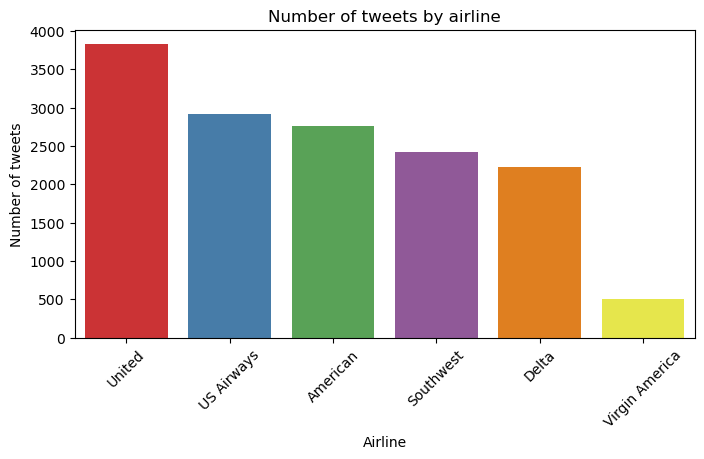

In [29]:
plt.figure(figsize = (8,4))
sns.countplot(x = 'airline', data = df_tweets, order = df_tweets['airline'].value_counts().index, palette = 'Set1') #seaborn countplot
plt.title("Number of tweets by airline")
plt.xlabel("Airline")
plt.ylabel("Number of tweets")
plt.xticks(rotation=45)
plt.show()

C:\Users\Sonal Thorat\AppData\Local\Temp\ipykernel_18904\1295977724.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


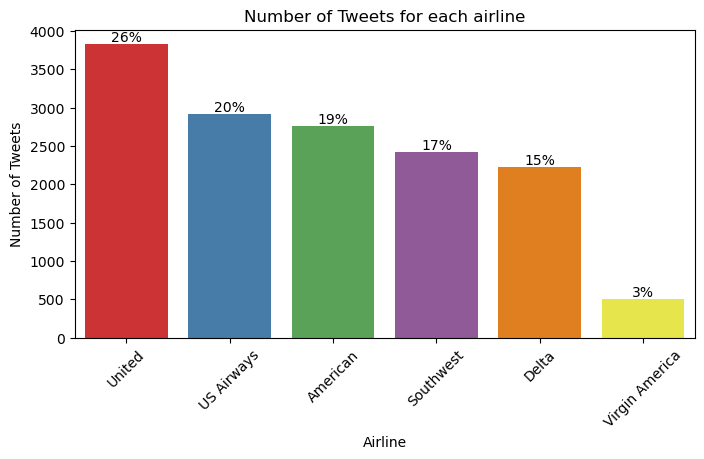

In [30]:
plt.figure(figsize=(8,4))

# Create the countplot
ax = sns.countplot(
    x='airline',
    data=df_tweets,
    order=df_tweets['airline'].value_counts().index,
    palette='Set1'
)

plt.title("Number of Tweets for each airline")
plt.xlabel("Airline")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=45)

# --- Add percentage labels ---
total = len(df_tweets)
for p in ax.patches:
    count = p.get_height()
    percentage = 100 * count / total
    ax.annotate(f'{percentage:.0f}%',
                (p.get_x() + p.get_width() / 2., count),
                ha='center', va='bottom',
                fontsize=10, color='black')

plt.show()

#### Q.3. How many tweets are there by `each airline` and `each category`?

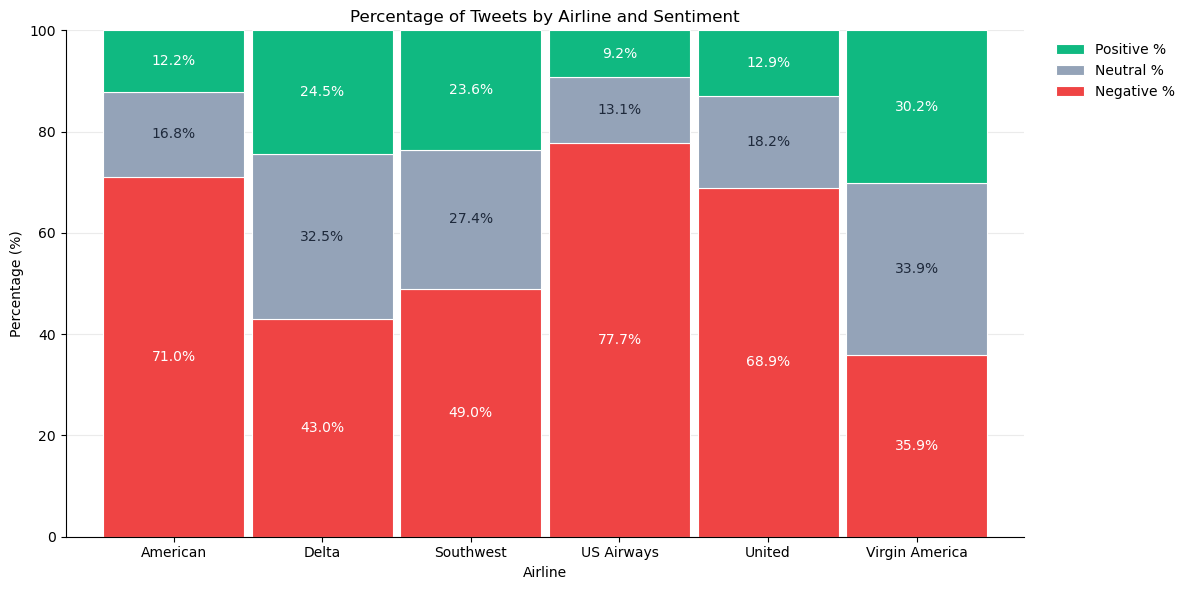

In [31]:
colors = {"negative": "#ef4444", "neutral": "#94a3b8", "positive": "#10b981"}  # red, slate grey, green
order = ["negative", "neutral", "positive"]

# Row-wise percentages: each airline's bar sums to 100
pct = pd.crosstab(data["airline"], data["airline_sentiment"], normalize="index")[order] * 100

ax = pct.plot(kind="bar", stacked=True, figsize=(12, 6), width=0.95,
              color=[colors[s] for s in order], edgecolor="white", linewidth=0.8)

# Centered % labels: white on red/green, dark on grey
for container, s in zip(ax.containers, order):
    ax.bar_label(container, labels=[f"{v:.1f}%" for v in pct[s]], label_type="center",
                 fontsize=10, color="#1e293b" if s == "neutral" else "white")

ax.set_title("Percentage of Tweets by Airline and Sentiment")
ax.set_xlabel("Airline")
ax.set_ylabel("Percentage (%)")
ax.set_ylim(0, 100)
ax.set_xticklabels(pct.index, rotation=0)
ax.grid(axis="y", alpha=0.25); ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

# Legend on the right, top-to-bottom order matches the stack (Positive, Neutral, Negative)
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles[::-1], ["Positive %", "Neutral %", "Negative %"],
          bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)

plt.tight_layout()
plt.show()

### `Pankaj & Vivek` I will add the `wordcloud` later and explain tmrw (10/25)

In [32]:
df_tweets['text']

0                      @VirginAmerica What @dhepburn said.
1        @VirginAmerica plus you've added commercials t...
2        @VirginAmerica I didn't today... Must mean I n...
3        @VirginAmerica it's really aggressive to blast...
4        @VirginAmerica and it's a really big bad thing...
                               ...                        
14635    @AmericanAir thank you we got on a different f...
14636    @AmericanAir leaving over 20 minutes Late Flig...
14637    @AmericanAir Please bring American Airlines to...
14638    @AmericanAir you have my money, you change my ...
14639    @AmericanAir we have 8 ppl so we need 2 know h...
Name: text, Length: 14640, dtype: object

---
# 🅱️ PART B — Project: ✈️ Twitter US Airline Passenger Sentiment Prediction

---
## 1. Business Problem

Airlines receive **thousands of tweets per day**. Customer-service teams can't read them all.

**Goal:** Build a model that reads a tweet and predicts whether the passenger is **negative 😠, neutral 😐 or positive 😊**, so that:
* negative tweets are **routed to support agents first**,
* management gets a **real-time sentiment dashboard** per airline,
* recurring complaint themes (late flights, lost luggage) are surfaced.

### 📦 Dataset — `Tweets.csv` (Kaggle / Figure Eight "Twitter US Airline Sentiment")
| Column | Description |
|---|---|
| `text` | the tweet ✅ **our input** |
| `airline_sentiment` | negative / neutral / positive ✅ **our target** |
| `airline_sentiment_confidence` | annotator agreement (0–1) |
| `negativereason` | why the tweet is negative (Late Flight, Customer Service Issue …) |
| `airline` | Virgin America, United, Southwest, Delta, US Airways, American |
| others | tweet id, user name, retweets, location, timezone, created time |

### 🔄 Project workflow
`Load → EDA → Clean tweets → NLP pipeline preprocessing → TF-IDF → Train models → Evaluate → Interpret → Error analysis → Predict new tweets`

In [33]:
df = pd.read_csv("Tweets.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'Tweets.csv'

In [ ]:
df.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760000,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,24-02-2015 11:35,NaN,Eastern Time (US & Canada)
1,570301130888122000,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,24-02-2015 11:15,NaN,Pacific Time (US & Canada)
2,570301083672813000,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,24-02-2015 11:15,Lets Play,Central Time (US & Canada)
3,570301031407624000,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,24-02-2015 11:15,NaN,Pacific Time (US & Canada)
4,570300817074462000,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,24-02-2015 11:14,NaN,Pacific Time (US & Canada)


In [ ]:
df.shape

(14640, 15)

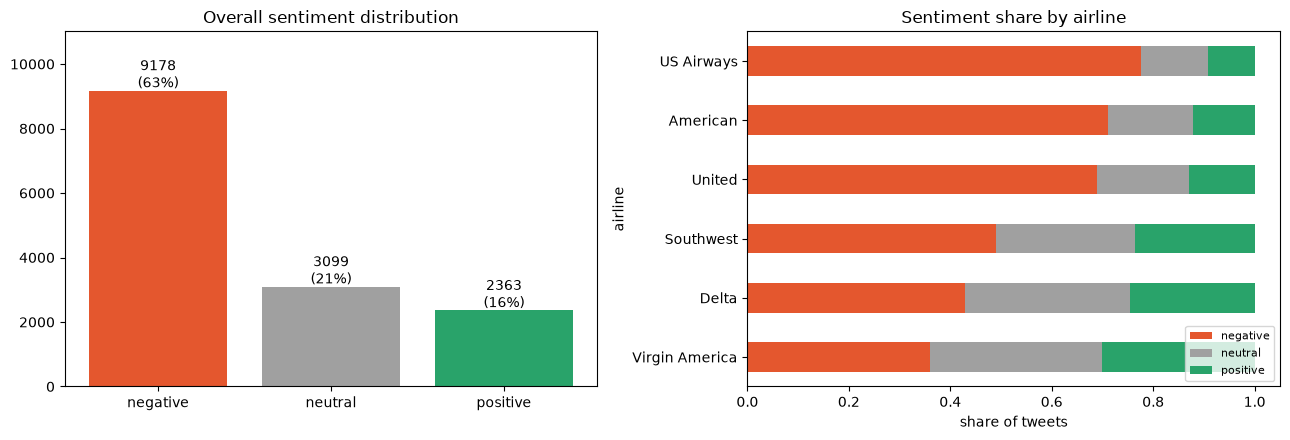

In [ ]:
SENT_COLORS = {"negative": "#e4572e", "neutral": "#a0a0a0", "positive": "#29a36a"}
SENT_ORDER = ["negative", "neutral", "positive"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

counts = data["airline_sentiment"].value_counts().reindex(SENT_ORDER)
ax[0].bar(counts.index, counts.values, color=[SENT_COLORS[s] for s in counts.index])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 100, f"{v}\n({v/len(data):.0%})", ha="center")
ax[0].set_title("Overall sentiment distribution")
ax[0].set_ylim(0, counts.max() * 1.2)

ct = pd.crosstab(data["airline"], data["airline_sentiment"], normalize="index")[SENT_ORDER]
ct.sort_values("negative").plot(kind="barh", stacked=True, ax=ax[1],
                                color=[SENT_COLORS[s] for s in SENT_ORDER])
ax[1].set_title("Sentiment share by airline")
ax[1].set_xlabel("share of tweets")
ax[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

📌 **Observations**
* The dataset is **imbalanced** — about **63% negative**. People tweet at airlines mostly to complain!
  → *Accuracy alone will be misleading*; we'll use **macro-F1** and the confusion matrix.
* **US Airways, American and United** have the highest negative share; **Virgin America** the lowest.

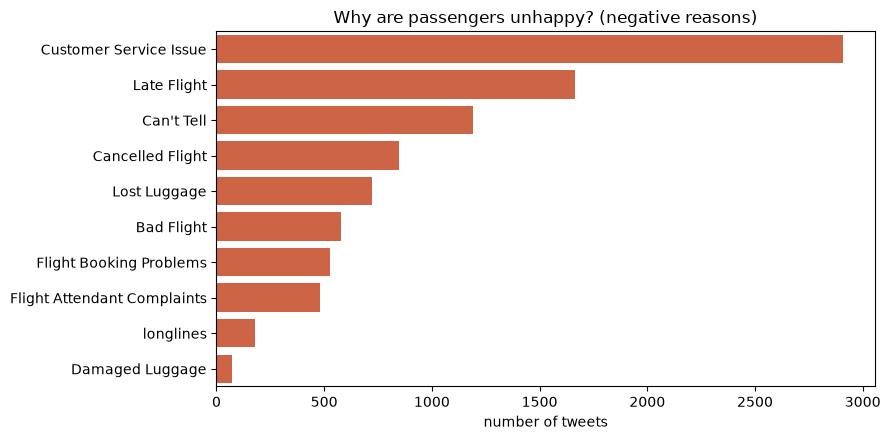

In [ ]:
neg = data[data["airline_sentiment"] == "negative"]
reasons = neg["negativereason"].value_counts()

plt.figure(figsize=(9, 4.5))
sns.barplot(x=reasons.values, y=reasons.index, color="#e4572e")
plt.title("Why are passengers unhappy? (negative reasons)")
plt.xlabel("number of tweets"); plt.ylabel("")
plt.tight_layout(); plt.show()

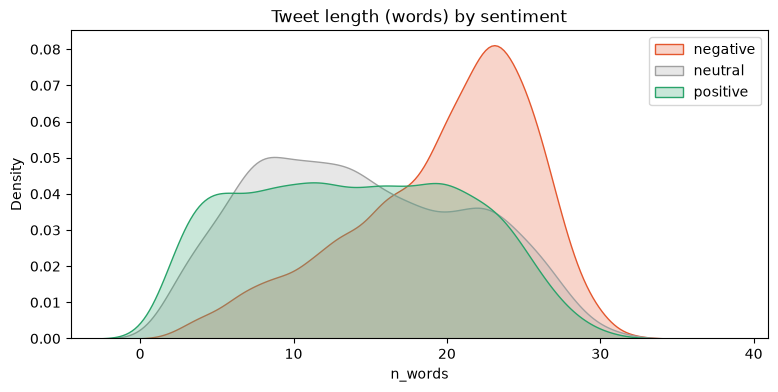

,n_words,n_chars
airline_sentiment,,
negative,19.7,113.9
neutral,14.4,87.4
positive,14.0,86.1


In [ ]:
data["n_words"] = data["text"].str.split().str.len() #splitting each tweet on whitespaces into a **list of words** and then counts the items in each list
data["n_chars"] = data["text"].str.len() #counting the number of characters

plt.figure(figsize =(9,4))
for s in SENT_ORDER:
    sns.kdeplot(data.loc[data["airline_sentiment"] == s, "n_words"], label = s, color= SENT_COLORS[s], fill=True, alpha = .25)
plt.title("Tweet length (words) by sentiment");plt.legend();plt.show()

data.groupby("airline_sentiment")[["n_words", "n_chars"]].mean().round(1)

📌 **Observation:** Negative tweets are **longer** — angry customers explain their story; happy customers just say *"thanks!"*.

##  Tweet Cleaning — Social-media Specific Noise

Tweets contain things that confuse classic NLP:

| Noise | Example | Action |
|---|---|---|
| @mentions | `@united` | remove (every tweet mentions an airline — no signal; also leaks airline identity) |
| URLs | `http://t.co/abc` | remove |
| HTML entities | `&amp;`, `&lt;` | decode / remove |
| Hashtags | `#fail`, `#customerservice` | keep the **word**, drop `#` |
| Numbers / flight numbers | `UA1234`, `3hrs` | remove digits |
| Emoticons | `:)`, `:(` | convert to words: ` smile `, ` sad ` (they carry sentiment!) |
| Elongations | `sooooo`, `pleaseeee` | squeeze to max 2 letters |
| Contractions | `can't`, `wasn't` | expand → keeps the negation |

In [ ]:
import html

CONTRACTIONS = {
    "won't": "will not", "can't": "can not", "n't": " not", "'re": " are", "'s": " is",
    "'d": " would", "'ll": " will", "'ve": " have", "'m": " am",
}
EMOTICONS = {
    r"[:;=]-?\)+|\(-?[:;=]|<3": " emo_pos ",
    r"[:;=]-?\(+|\)-?[:;=]|:'\(": " emo_neg ",
    r"[:;=]-?D\b": " emo_pos ",
}

def clean_tweet(text):
    text = html.unescape(text) #&amp; -> & #decodes HTML entities
    for pat, rep in EMOTICONS.items():
        text = re.sub(pat, rep, text) # emoticons --> tokens (before punctuation removal) - replacing faces with tokens :( -> emo_neg :D -> D
    text = text.lower() # converting to lowercase
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)          #URLs - removing http or https upto the next whitespace
    text = re.sub(r"@\w+", " ", text)                           # @mentions removed for ex: @united -> gone from the data
    text = text.replace("’", "'")                               # replacing curly apostrophe to plain one
    for c, full in CONTRACTIONS.items():                        # expand contractions
        text = text.replace(c, full)                            # expands contractions using the table above
    text = re.sub(r"#", " ", text)                              # dropping the hashtag while keeping the word
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)                  # sooooo -> soo #elognations get compressed
    text = re.sub(r"[^a-z_\s]", " ", text)                      # digits, punctuation, emojis
    text = re.sub(r"\s+", " ", text).strip()
    return text

In [ ]:
examples = data["text"].sample(6, random_state=34).tolist() + [
    "@united you LOST my bag AGAIN &amp; won't call back :( #fail http://t.co/xyz",
    "@VirginAmerica soooo happy with the flight :) thanks!!!"]
for t in examples:
    print(f"RAW  : {t}\nCLEAN: {clean_tweet(t)}\n")

RAW  : @AmericanAir just need to know why it wasn't done like it was promised it would yesterday
CLEAN: just need to know why it was not done like it was promised it would yesterday

RAW  : @SouthwestAir I understand. Wonderful "Miriam" in customer service who was able to reroute me... Got any rental car discounts?
CLEAN: i understand wonderful miriam in customer service who was able to reroute me got any rental car discounts

RAW  : @JetBlue I know there's no actual 'mile high' club, but surely there's something I can join ;-)
CLEAN: i know there is no actual amile high club but surely there is something i can join emo_pos

RAW  : @JetBlue ...second incident of lost baggage.  I sent you a DM.  Thoughts?
CLEAN: second incident of lost baggage i sent you a dm thoughts

RAW  : @united hold for 30 minutes finally got someone and they retook my form of payment and confirmed that my reservation was set. I tried to
CLEAN: hold for minutes finally got someone and they retook my form of paymen

##### `Vivek's Question`
RAW : jOHN MESSAGES TO MARIA GO TO GOSSAARY STORE AS SOON AS POSSIBLE

CLEANED : John msges Maria go gossary store ASAP

is it correct ???


In [ ]:
text = "jOHN MESSAGES TO MARIA GO TO GOSSAARY STORE AS SOON AS POSSIBLE"
print("RAW :", text)
print("CLEAN:", clean_tweet(text))

RAW : jOHN MESSAGES TO MARIA GO TO GOSSAARY STORE AS SOON AS POSSIBLE
CLEAN: john messages to maria go to gossaary store as soon as possible


##  Applying the NLP Pipeline to Tweets

Now we reuse the Part A steps. We'll build **one configurable function** so we can **experiment** with which steps help.

| Pipeline step | Used here? | Why |
|---|---|---|
| Sentence segmentation | ❌ | tweets are short — treat each as one document |
| Word tokenization | ✅ | `TweetTokenizer` / `word_tokenize` |
| Stop-word removal | ✅ (custom) | **keep negations** — critical for sentiment |
| Stemming *or* Lemmatization | ✅ (compare both) | shrink vocabulary |
| POS tagging | ✅ (inside lemmatization) | for correct lemmas |
| Dependency parsing | ❌ | not needed for document-level classification (but see bonus) |
| NER | 🔎 for analytics | find *where* the problems are (Section 10) |

In [ ]:
import re
import string
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
import spacy
from spacy import displacy

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

# NLTK resources (names differ across NLTK versions, so we fetch both old & new)
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng",
            "maxent_ne_chunker", "maxent_ne_chunker_tab", "words"]:
    nltk.download(pkg, quiet=True)

# spaCy English model
try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    from spacy.cli import download
    download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm")

print("NLTK :", nltk.__version__)
print("spaCy:", spacy.__version__)

NLTK : 3.10.0
spaCy: 3.8.14


In [ ]:
import re, html
import nltk
from nltk import pos_tag
from nltk.tokenize import TweetTokenizer, word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, WordNetLemmatizer

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

porter = PorterStemmer()
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))

NEGATIONS = {"no", "not", "nor", "never", "n't", "none", "nobody", "nothing", "neither", "nowhere",
             "don't", "didn't", "doesn't", "wasn't", "weren't", "isn't", "aren't", "won't", "wouldn't",
             "can't", "couldn't", "shouldn't", "hasn't", "haven't", "hadn't"}

def penn_to_wordnet(tag):
    if tag.startswith("J"): return wordnet.ADJ
    if tag.startswith("V"): return wordnet.VERB
    if tag.startswith("R"): return wordnet.ADV
    return wordnet.NOUN

In [ ]:
tweet_tok = TweetTokenizer()
SENTIMENT_STOP = (stop_words - NEGATIONS) | {"flight", "flights", "amp"}  # domain words carry no sentiment

def preprocess(text, normalizer="lemma", remove_stop=True):
    """clean -> tokenize -> (stop words) -> (stem | lemma)"""
    tokens = tweet_tok.tokenize(clean_tweet(text))
    if remove_stop:
        tokens = [t for t in tokens if t not in SENTIMENT_STOP]
    if normalizer == "stem":
        tokens = [porter.stem(t) for t in tokens]
    elif normalizer == "lemma":
        tokens = [lemmatizer.lemmatize(t, penn_to_wordnet(tag)) for t, tag in pos_tag(tokens)]
    tokens = [t for t in tokens if len(t) > 1]
    return " ".join(tokens)

### Example tweet
t = "@united The flights were delayed and the staff wasn't helping at all :( #worst"
print("raw      :", t)
print("clean    :", clean_tweet(t))
print("no-norm  :", preprocess(t, normalizer=None))
print("stemmed  :", preprocess(t, normalizer="stem"))
print("lemmatized:", preprocess(t, normalizer="lemma"))

raw      : @united The flights were delayed and the staff wasn't helping at all :( #worst
clean    : the flights were delayed and the staff was not helping at all emo_neg worst
no-norm  : delayed staff not helping emo_neg worst
stemmed  : delay staff not help emo_neg worst
lemmatized: delayed staff not help emo_neg bad


In [ ]:
%%time
# Build three versions of the corpus so we can compare them (≈30–60 s for the lemma version)
data["clean"] = data["text"].apply(lambda x: preprocess(x, normalizer=None, remove_stop=False))
data["stem"]  = data["text"].apply(lambda x: preprocess(x, normalizer="stem"))
data["lemma"] = data["text"].apply(lambda x: preprocess(x, normalizer="lemma"))
data[["text", "clean", "stem", "lemma"]].head(8)

CPU times: total: 11.8 s
Wall time: 11.8 s


,text,clean,stem,lemma
0,@VirginAmerica What @dhepburn said.,what said,said,say
1,@VirginAmerica plus you've added commercials to the experience... tacky.,plus you have added commercials to the experience tacky,plu ad commerci experi tacki,plus added commercial experience tacky
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,did not today must mean need to take another trip,not today must mean need take anoth trip,not today must mean need take another trip
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have littl...",it is really aggressive to blast obnoxious entertainment in your guests faces they have little recourse,realli aggress blast obnoxi entertain guest face littl recours,really aggressive blast obnoxious entertainment guest face little recourse
4,@VirginAmerica and it's a really big bad thing about it,and it is really big bad thing about it,realli big bad thing,really big bad thing
5,@VirginAmerica seriously would pay $30 a flight for seats that didn't have this playing.\nit's really the only bad t...,seriously would pay flight for seats that did not have this playing it is really the only bad thing about flying va,serious would pay seat not play realli bad thing fli va,seriously would pay seat not play really bad thing fly va
6,"@VirginAmerica yes, nearly every time I fly VX this “ear worm” won’t go away :)",yes nearly every time fly vx this ear worm will not go away emo_pos,ye nearli everi time fli vx ear worm not go away emo_po,yes nearly every time fly vx ear worm not go away emo_pos
7,"@VirginAmerica Really missed a prime opportunity for Men Without Hats parody, there. https://t.co/mWpG7grEZP",really missed prime opportunity for men without hats parody there,realli miss prime opportun men without hat parodi,really missed prime opportunity men without hat parody


In [ ]:
# Stop-word & vocabulary analysis on the real data
for col in ["clean", "stem", "lemma"]:
    vocab = Counter(" ".join(data[col]).split())
    print(f"{col:6s} vocabulary size: {len(vocab):6,d}")

raw_tokens = " ".join(data["clean"]).split()
print(f"\nShare of stop words in cleaned tweets: {np.mean([w in stop_words for w in raw_tokens]):.0%}")

clean  vocabulary size: 11,112
stem   vocabulary size:  8,327
lemma  vocabulary size:  9,395

Share of stop words in cleaned tweets: 45%


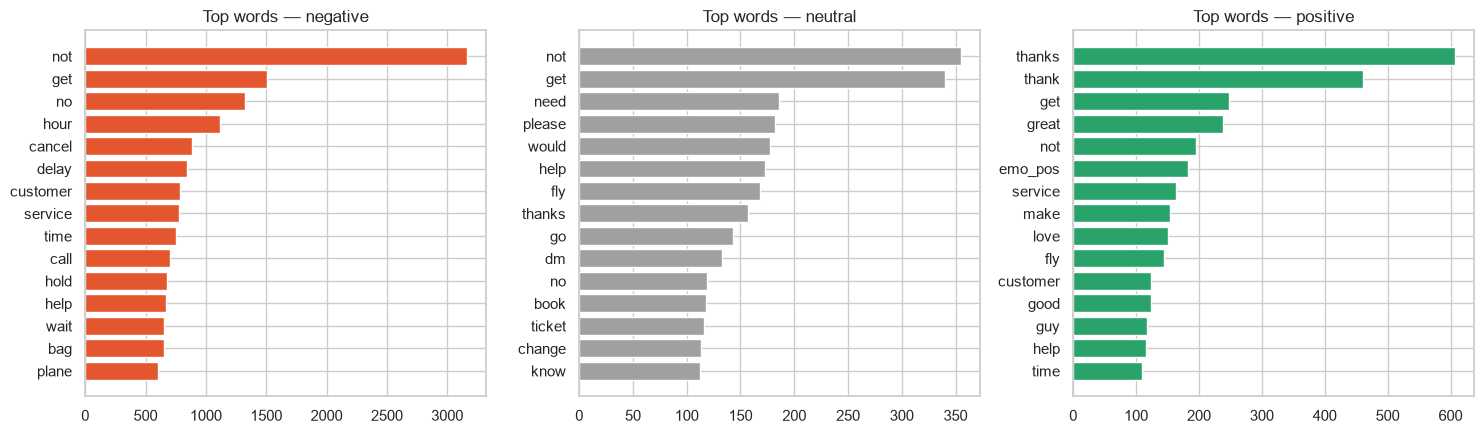

In [ ]:
# Most frequent words per sentiment (after preprocessing)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, s in zip(axes, SENT_ORDER):
    top = Counter(" ".join(data.loc[data["airline_sentiment"] == s, "lemma"]).split()).most_common(15)
    words_, freqs = zip(*top)
    ax.barh(words_[::-1], freqs[::-1], color=SENT_COLORS[s])
    ax.set_title(f"Top words — {s}")
plt.tight_layout(); plt.show()

📌 **Observation:** `not`, `cancel`, `delay`, `hour`, `hold`, `bag` dominate negative tweets; `thank`, `great`, `love`, `best` dominate positive ones. Neutral tweets are mostly **questions** (`help`, `need`, `get`, `fly`).
👉 That's why **keeping `not`** was essential.

## 6. Train / Test Split
We use a **stratified** split so each set keeps the same 63/21/16 class ratio.

In [ ]:
from sklearn.model_selection import train_test_split

y= data["airline_sentiment"]#target variable
idx_train, idx_test = train_test_split(data.index, test_size=0.2, stratify=y, random_state=42)
y_train, y_test = y.loc[idx_train], y.loc[idx_test]
print("Train:", len(idx_train), " Test:", len(idx_test))
print(y_train.value_counts(normalize=True).round(3))

Train: 11712  Test: 2928
airline_sentiment
negative    0.627
neutral     0.212
positive    0.161
Name: proportion, dtype: float64


In [ ]:
y[:10]

0     neutral
1    positive
2     neutral
3    negative
4    negative
5    negative
6    positive
7     neutral
8    positive
9    positive
Name: airline_sentiment, dtype: str

In [ ]:
2928/(11712+2928)*100

20.0

## Baseline & Model Comparison

We compare:
* **3 preprocessing variants** — clean only / stemmed / lemmatized
* **4 classic text classifiers** — Multinomial Naive Bayes, Logistic Regression, Linear SVM, and Random Forest (a tree ensemble, added for contrast with the linear models)

All use **TF-IDF with unigrams + bigrams**, wrapped in a scikit-learn `Pipeline` (so the vectorizer is fit **only on training data** → no leakage).

**Metric:** `macro-F1` = average F1 over the 3 classes, treating minority classes as equally important.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score


def make_pipe(model):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("clf", model),
    ])

models = {
    "Baseline (always 'negative')": DummyClassifier(strategy="most_frequent"),
    "Naive Bayes":         MultinomialNB(alpha=0.3),
    "Logistic Regression": LogisticRegression(max_iter=2000, C=3, class_weight="balanced"),
    "Linear SVM":          LinearSVC(C=0.5, class_weight="balanced"),
    # Tree ensemble on sparse TF-IDF: slowest of the four to train (3 fits x ~200 trees), so expect a wait.
    "Random Forest":       RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                                  n_jobs=-1, random_state=42),
}

results =[]
for text_col in ["clean", "stem", "lemma"]:
    for name, model in models.items():
        pipe = make_pipe(model).fit(data.loc[idx_train, text_col], y_train) #training
        pred = pipe.predict(data.loc[idx_test, text_col])
        results.append({"preprocessing" : text_col, "model": name,
                        "accuracy" : accuracy_score(y_test, pred),
                        "macro_F1" : f1_score(y_test, pred, average="macro")})

from IPython.display import display

res = pd.DataFrame(results)

for metric in ["accuracy", "macro_F1"]:
    print(f"\n=== {metric} ===")
    display(
        res.pivot(index="model", columns="preprocessing", values=metric)
           .round(3)
           .style.background_gradient(cmap="Greens", axis=None)
    )


=== accuracy ===


preprocessing,clean,lemma,stem
model,,,
Baseline (always 'negative'),0.627000,0.627000,0.627000
Linear SVM,0.807000,0.794000,0.791000
Logistic Regression,0.796000,0.781000,0.785000
Naive Bayes,0.758000,0.756000,0.758000
Random Forest,0.778000,0.791000,0.795000



=== macro_F1 ===


preprocessing,clean,lemma,stem
model,,,
Baseline (always 'negative'),0.257000,0.257000,0.257000
Linear SVM,0.745000,0.729000,0.726000
Logistic Regression,0.742000,0.726000,0.731000
Naive Bayes,0.637000,0.634000,0.638000
Random Forest,0.686000,0.717000,0.724000
